In [13]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("resale_car_clean.csv")

print("数据规模：", df.shape)
display(df.head())

数据规模： (1445, 16)


,Price,Manufacturing_year,Engine capacity,KM driven,Ownership,Imperfections,Repainted Parts,model,USD_price,Fuel type_CNG,Fuel type_Diesel,Fuel type_Petrol,Spare key_No,Spare key_Yes,Transmission_Automatic,Transmission_Manual
0,561000,2017,1197,25847,2,6,2,Maruti Swift VXI,6171.0,0,0,1,1,0,0,1
1,498000,2016,1197,55511,2,12,1,Maruti Baleno DELTA PETROL 1.2,5478.0,0,0,1,0,1,0,1
2,577000,2020,1197,47110,1,4,2,Maruti Swift VXI,6347.0,0,0,1,1,0,0,1
3,1084000,2022,1462,35378,1,2,3,Maruti Ertiga VXI AT SHVS,11924.0,0,0,1,0,1,1,0
4,603000,2019,1197,91856,1,3,2,Maruti Dzire VXI,6633.0,0,0,1,0,1,0,1


In [15]:
eda = df[
    [
        "USD_price",
        "Manufacturing_year",
        "KM driven",
        "Ownership",
        "Imperfections",
    ]
].rename(columns={
    "USD_price": "Price (USD)",
    "Manufacturing_year": "Manufacturing year",
    "KM driven": "Mileage (km)",
    "Ownership": "Ownership",
    "Imperfections": "Imperfections",
})

display(eda.describe())

,Price (USD),Manufacturing year,Mileage (km),Ownership,Imperfections
count,1445.000000,1445.000000,1445.000000,1445.000000,1445.000000
mean,5789.897578,2017.817301,50588.903114,1.285121,9.597232
std,2160.065871,2.986554,27339.562631,0.489877,8.398637
min,1529.000000,2010.000000,1207.000000,1.000000,0.000000
25%,4290.000000,2016.000000,28803.000000,1.000000,3.000000
50%,5511.000000,2018.000000,47849.000000,1.000000,8.000000
75%,6941.000000,2020.000000,70337.000000,2.000000,14.000000
max,17589.000000,2023.000000,124716.000000,3.000000,43.000000


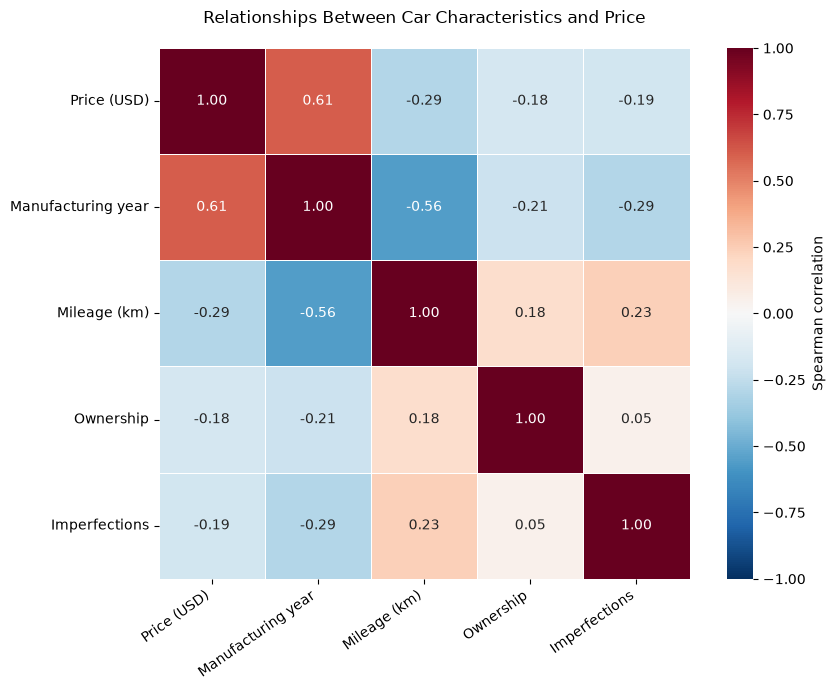

In [16]:
# Calculate correlations between the five numerical variables
corr = eda.corr(method="spearman")

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title("Relationships Between Car Characteristics and Price", pad=18)
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda1_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

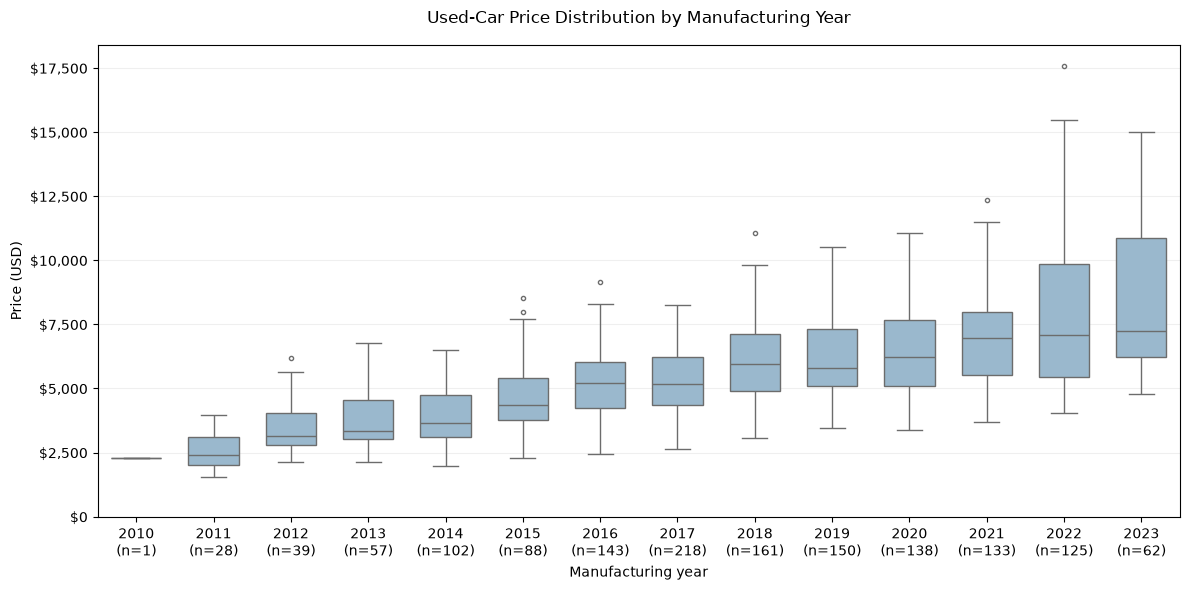

In [17]:
from matplotlib.ticker import StrMethodFormatter
from pathlib import Path

# 按年份从早到晚排列，并统计每年的样本数
years = sorted(df["Manufacturing_year"].dropna().unique())
year_counts = df.groupby("Manufacturing_year")["USD_price"].count()

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Manufacturing_year",
    y="USD_price",
    order=years,
    color="#91b9d6",
    width=0.65,
    fliersize=3,
    ax=ax
)

# 每个年份下标出样本数
ax.set_xticks(range(len(years)))
ax.set_xticklabels([
    f"{int(year)}\n(n={year_counts.loc[year]})"
    for year in years
])

ax.set_title("Used-Car Price Distribution by Manufacturing Year", pad=16)
ax.set_xlabel("Manufacturing year")
ax.set_ylabel("Price (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig(
    "figures/eda2_price_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
# 查看 model 第一段的分布，初步检查品牌
brand_check = df["model"].str.strip().str.split().str[0]

display(brand_check.value_counts())

model
Maruti    1445
Name: count, dtype: int64

In [19]:
# 查看完整车型名称及数量，先不修改原始数据
model_counts = df["model"].value_counts()

print("不同车型/配置名称的数量：", len(model_counts))
display(model_counts.head(30))

不同车型/配置名称的数量： 212


model
Maruti Swift VXI                        81
Maruti Baleno DELTA PETROL 1.2          72
Maruti Wagon R 1.0 VXI                  63
Maruti Baleno ZETA PETROL 1.2           52
Maruti Alto K10 VXI                     34
Maruti Alto 800 LXI                     31
Maruti S PRESSO VXI+                    31
Maruti Baleno ZETA CVT PETROL 1.2       30
Maruti Baleno ALPHA PETROL 1.2          30
Maruti Swift Dzire VXI                  28
Maruti Wagon R 1.0 LXI CNG              26
Maruti Celerio ZXI AMT                  23
Maruti Celerio VXI AMT                  23
Maruti Wagon R 1.0 LXI                  22
Maruti Dzire VXI                        18
Maruti IGNIS DELTA 1.2                  18
Maruti Celerio ZXI                      17
Maruti Wagon R 1.0 VXI AMT              17
Maruti Ciaz ALPHA AT 1.5 SHVS PETROL    17
Maruti Baleno DELTA CVT PETROL 1.2      17
Maruti Alto VXI                         16
Maruti Baleno ALPHA CVT PETROL 1.2      16
Maruti Alto LXI                         16
Marut

In [20]:
# 仅用于检查名称，不作为最终车型分类
prefixes = model_names.str.split().str[:2].str.join(" ")

print("不同前缀数量：", prefixes.nunique())
print("\n".join(sorted(prefixes.unique())))

不同前缀数量： 63
A Star
Alto 800
Alto K10
Alto LXI
Alto VXI
BREZZA VXI
BREZZA ZXI
Baleno ALPHA
Baleno DELTA
Baleno RS
Baleno SIGMA
Baleno ZETA
Celerio LXI
Celerio VXI
Celerio X
Celerio ZXI
Ciaz ALPHA
Ciaz DELTA
Ciaz S
Ciaz SIGMA
Ciaz VDI
Ciaz VXI
Ciaz VXI+
Ciaz ZDI
Ciaz ZETA
Ciaz ZXI
Ciaz ZXI+
Dzire LXI
Dzire VDI
Dzire VXI
Dzire ZXI
Eeco 5
Ertiga LXI
Ertiga VDI
Ertiga VXI
Ertiga ZDI
Ertiga ZXI
Ertiga ZXI+
Grand Vitara
IGNIS ALPHA
IGNIS DELTA
IGNIS SIGMA
IGNIS ZETA
New Wagon-R
OMNI E
Omni 5
Ritz LXI
Ritz VDI
Ritz VXI
Ritz ZDI
S Cross
S PRESSO
Swift Dzire
Swift LXI
Swift VDI
Swift VXI
Swift ZDI
Swift ZXI
Vitara Brezza
Wagon R
XL6 ALPHA
XL6 ZETA
Zen Estilo


In [21]:
import re

# 前缀 → 统一后的车型名称
model_rules = {
    "NEW WAGON R": "Wagon R",
    "WAGON R": "Wagon R",
    "SWIFT DZIRE": "Swift Dzire",
    "VITARA BREZZA": "Vitara Brezza",
    "GRAND VITARA": "Grand Vitara",
    "ZEN ESTILO": "Zen Estilo",
    "ALTO 800": "Alto 800",
    "ALTO K10": "Alto K10",
    "CELERIO X": "Celerio X",
    "A STAR": "A Star",
    "S CROSS": "S Cross",
    "S PRESSO": "S Presso",
    "ALTO": "Alto",
    "BREZZA": "Brezza",
    "BALENO": "Baleno",
    "CELERIO": "Celerio",
    "CIAZ": "Ciaz",
    "DZIRE": "Dzire",
    "EECO": "Eeco",
    "ERTIGA": "Ertiga",
    "IGNIS": "Ignis",
    "OMNI": "Omni",
    "RITZ": "Ritz",
    "SWIFT": "Swift",
    "XL6": "XL6",
}

# 长名称优先，防止 Swift Dzire 被提前匹配为 Swift
ordered_prefixes = sorted(model_rules, key=len, reverse=True)

def extract_model(name):
    if pd.isna(name):
        return "Unmatched"

    name = str(name).upper().strip()
    name = re.sub(r"^MARUTI\s+", "", name)
    name = re.sub(r"[-–]+", " ", name)
    name = re.sub(r"\s+", " ", name)

    for prefix in ordered_prefixes:
        if name == prefix or name.startswith(prefix + " "):
            return model_rules[prefix]

    return "Unmatched"

# 新增一列，保留原始 model
df["model_group"] = df["model"].apply(extract_model)

model_counts = df["model_group"].value_counts()
print(model_counts.to_string())

# 检查是否遗漏
unmatched = df.loc[df["model_group"] == "Unmatched", "model"]
print("\n未匹配的记录数：", len(unmatched))
if not unmatched.empty:
    print(unmatched.unique())

model_group
Baleno           236
Wagon R          235
Swift            151
Ciaz             139
Celerio          129
Alto K10          69
S Presso          68
Dzire             66
Ignis             65
Swift Dzire       61
Alto              49
Alto 800          43
Ertiga            32
Vitara Brezza     29
XL6               21
Brezza            15
Celerio X         12
Eeco               8
Ritz               7
S Cross            3
Grand Vitara       2
Omni               2
A Star             2
Zen Estilo         1

未匹配的记录数： 0


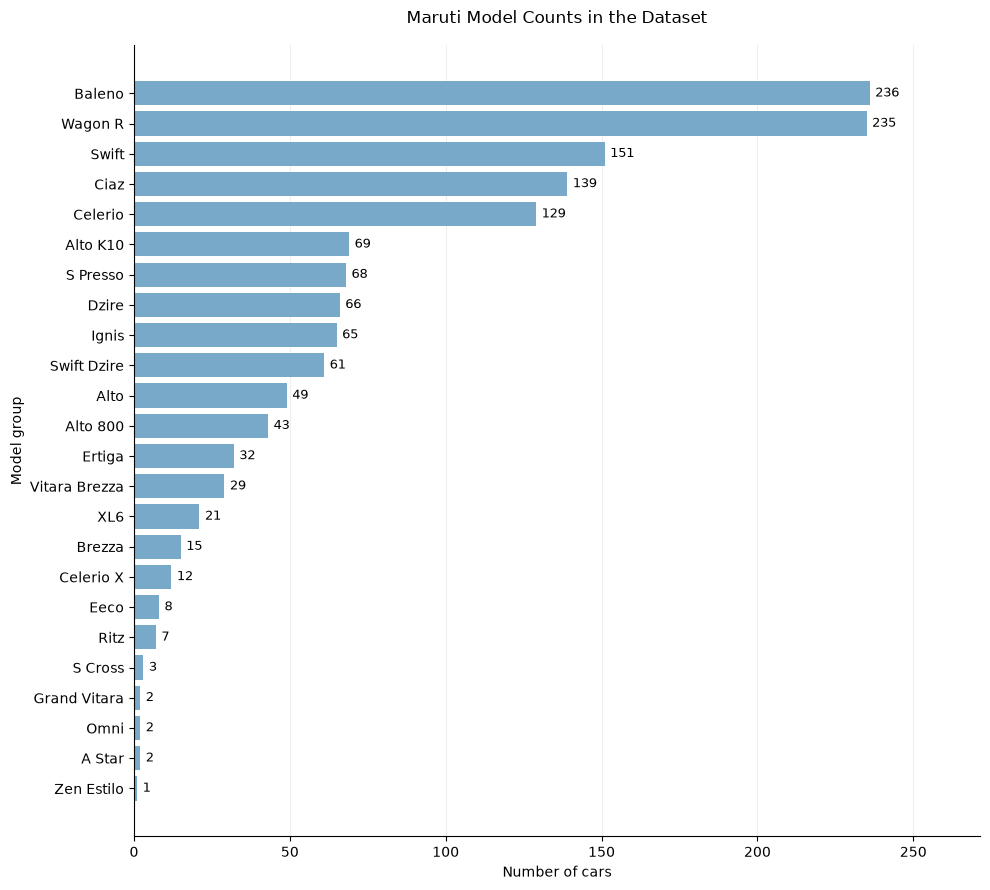

In [22]:
from pathlib import Path

# 从多到少排列
model_counts = df["model_group"].value_counts()

fig, ax = plt.subplots(figsize=(10, 9))

bars = ax.barh(
    model_counts.index,
    model_counts.values,
    color="#79a9c9"
)

# 数量最多的排在最上面
ax.invert_yaxis()

# 在每根柱子末尾标出数量
ax.bar_label(bars, padding=4, fontsize=9)

ax.set_title("Maruti Model Counts in the Dataset", pad=16)
ax.set_xlabel("Number of cars")
ax.set_ylabel("Model group")
ax.set_xlim(0, model_counts.max() * 1.15)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
sns.despine(ax=ax)

fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig(
    "figures/eda5_model_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()